# Implementación de un modelo de clasificación como servicio web con FastAPI

**Materia:** Toma de Decisiones  
**Estudiante:** Jhonatan David Pérez Siachoque  
**Institución:** Universidad Pedagógica y Tecnológica de Colombia  
**Entorno:** Google Colab / Python 3

## Objetivo

Entrenar un modelo de clasificación Random Forest, convertirlo en una API REST mediante FastAPI, probarla con solicitudes HTTP, y registrar métricas y errores para monitorear su funcionamiento.

**Resultados esperados:** `/predict`, `/predict/batch`, `/health`, `/metrics`, `/schema`, `/example`, OpenAPI/Swagger, validación de entradas, logs y pruebas automatizadas.

> **Advertencia:** este dataset representa mediciones de muestras mamarias, pero el ejemplo es exclusivamente didáctico. **No es un diagnóstico ni un servicio clínico.** El modelo se reentrena para esta práctica; no se reutiliza directamente el artefacto guardado en MLflow.

## 1. Instalar las dependencias

Ejecuta esta celda al inicio de una sesión nueva. Colab puede solicitar permisos y tardar algunos minutos.

In [ ]:
%pip -q install "fastapi>=0.115,<1" "uvicorn>=0.30,<1" "pydantic>=2.7,<3" "scikit-learn>=1.5,<2" "numpy>=1.26,<3" "joblib>=1.3,<2" "requests>=2.31,<3" "httpx>=0.27,<1" "pytest>=8,<10" "matplotlib>=3.7,<4"

## 2. Preparar las carpetas del proyecto

El cuaderno es **autocontenido**: crea los archivos Python necesarios en el almacenamiento temporal de Colab. No necesita clonar el repositorio ni subir ningún archivo adicional para funcionar.

In [ ]:
from pathlib import Path
for carpeta in ["app", "scripts", "tests", "artifacts", "examples", "logs", "evidencias"]:
    Path(carpeta).mkdir(parents=True, exist_ok=True)
Path("app/__init__.py").touch()
print("Carpetas y paquete app creados correctamente")

## 3. Programar el entrenamiento de Random Forest

Se utiliza el conjunto público **Breast Cancer Wisconsin** de scikit-learn, 30 variables numéricas, 455 ejemplos de entrenamiento y 114 de prueba. Se fija `random_state=42` para reproducibilidad.

In [ ]:
%%writefile scripts/train_model.py
"""Entrena el Random Forest del ejemplo y guarda artefactos reproducibles."""
from __future__ import annotations

import json
from datetime import datetime, timezone
from pathlib import Path

import joblib
import numpy as np
import sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split

ROOT = Path(__file__).resolve().parents[1]
ARTIFACTS = ROOT / "artifacts"
EXAMPLES = ROOT / "examples"


def train() -> dict:
    ARTIFACTS.mkdir(parents=True, exist_ok=True)
    EXAMPLES.mkdir(parents=True, exist_ok=True)
    dataset = load_breast_cancer()
    X = np.asarray(dataset.data, dtype=float)
    y = np.asarray(dataset.target, dtype=int)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=y
    )
    model = RandomForestClassifier(
        n_estimators=250, max_depth=8, random_state=42, n_jobs=1
    )
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    scores = {
        "accuracy": round(float(accuracy_score(y_test, pred)), 5),
        "precision_macro": round(float(precision_score(y_test, pred, average="macro")), 5),
        "recall_macro": round(float(recall_score(y_test, pred, average="macro")), 5),
        "f1_macro": round(float(f1_score(y_test, pred, average="macro")), 5),
        "matriz_confusion_0_maligno_1_benigno": confusion_matrix(y_test, pred).tolist(),
        "n_train": len(X_train),
        "n_test": len(X_test),
    }
    probabilities = model.predict_proba(X_test)
    def select_example(target_class: int) -> int:
        # Ejemplo correctamente clasificado con probabilidad no extrema,
        # más útil para interpretar las respuestas de una API demostrativa.
        options = [i for i in range(len(y_test)) if y_test[i] == target_class and pred[i] == target_class]
        return int(min(options, key=lambda i: abs(float(max(probabilities[i])) - 0.87)))

    chosen = select_example(0)  # Caso de etiqueta 0: maligno
    other = select_example(1)  # Caso de etiqueta 1: benigno
    example = {"features": [float(v) for v in X_test[chosen].tolist()]}
    example_other = {"features": [float(v) for v in X_test[other].tolist()]}
    metadata = {
        "model_name": "RandomForest_breast_cancer_demo",
        "version": "1.0.0",
        "target_labels": {"0": "maligno", "1": "benigno"},
        "feature_names": list(map(str, dataset.feature_names)),
        "n_features": X.shape[1],
        "dataset": "Breast Cancer Wisconsin Diagnostic / scikit-learn",
        "random_state": 42,
        "test_size": 0.20,
        "hyperparameters": {"n_estimators": 250, "max_depth": 8, "random_state": 42, "n_jobs": 1},
        "example": example,
        "example_expected_class_id": int(y_test[chosen]),
        "sklearn_version": sklearn.__version__,
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "disclaimer": "Demostración académica: no utilizar para decisiones médicas.",
    }
    joblib.dump(model, ARTIFACTS / "model.joblib", compress=3)
    (ARTIFACTS / "metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")
    (ARTIFACTS / "training_report.json").write_text(json.dumps(scores, indent=2, ensure_ascii=False), encoding="utf-8")
    (EXAMPLES / "sample_request.json").write_text(json.dumps(example, indent=2), encoding="utf-8")
    (EXAMPLES / "batch_request.json").write_text(json.dumps({"instances": [example, example_other]}, indent=2), encoding="utf-8")
    print("Modelo entrenado y exportado:", ARTIFACTS / "model.joblib")
    print("Métricas:", json.dumps(scores, ensure_ascii=False))
    return scores


if __name__ == "__main__":
    train()


## 4. Implementar la aplicación FastAPI

El servicio carga los artefactos al iniciarse; valida que el vector contenga **exactamente 30 números finitos**; registra un ID, el estado HTTP y la latencia de cada solicitud; y conserva contadores simples en memoria.

**Nota sobre el archivo `model.joblib`:** solo debe cargarse si se generó localmente y se confía en su procedencia, porque este formato no es seguro con archivos desconocidos.

In [ ]:
%%writefile app/main.py
"""Servicio REST educativo para inferencia con Random Forest."""
from __future__ import annotations

import json
import logging
import os
import time
import uuid
from collections import Counter
from contextlib import asynccontextmanager
from logging.handlers import RotatingFileHandler
from pathlib import Path
from threading import Lock
from typing import Literal

import joblib
import numpy as np
from fastapi import FastAPI, HTTPException, Request
from fastapi.responses import JSONResponse
from pydantic import BaseModel, Field, FiniteFloat

BASE_DIR = Path(__file__).resolve().parents[1]
ARTIFACT_DIR = Path(os.getenv("MODEL_DIR", str(BASE_DIR / "artifacts")))
LOG_DIR = BASE_DIR / "logs"
LOG_DIR.mkdir(parents=True, exist_ok=True)

logger = logging.getLogger("clasificador_api")
logger.setLevel(logging.INFO)
if not logger.handlers:
    formatter = logging.Formatter("%(asctime)s %(levelname)s %(message)s")
    file_handler = RotatingFileHandler(LOG_DIR / "servicio.log", maxBytes=500_000, backupCount=2, encoding="utf-8")
    file_handler.setFormatter(formatter)
    logger.addHandler(file_handler)
    stream = logging.StreamHandler()
    stream.setFormatter(formatter)
    logger.addHandler(stream)
logger.propagate = False

model = None
metadata: dict = {}
metrics_lock = Lock()
monitor = {"requests_total": 0, "errors_total": 0, "latency_ms_total": 0.0, "by_status": Counter()}


class FeaturesIn(BaseModel):
    """30 mediciones numéricas en el orden indicado por GET /schema."""
    features: list[FiniteFloat] = Field(min_length=30, max_length=30)


class BatchIn(BaseModel):
    instances: list[FeaturesIn] = Field(min_length=1, max_length=100)


class PredictOut(BaseModel):
    class_id: Literal[0, 1]
    prediction: Literal["maligno", "benigno"]
    confidence: float
    probabilities: dict[str, float]
    model_version: str


@asynccontextmanager
async def lifespan(application: FastAPI):
    global model, metadata
    model_path = ARTIFACT_DIR / "model.joblib"
    metadata_path = ARTIFACT_DIR / "metadata.json"
    if not model_path.exists() or not metadata_path.exists():
        raise RuntimeError("Modelo no encontrado. Ejecute: python scripts/train_model.py")
    # joblib/pickle: cargar únicamente modelos creados por nosotros y de origen confiable.
    model = joblib.load(model_path)
    metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
    logger.info("startup modelo=%s version=%s", metadata["model_name"], metadata["version"])
    yield
    logger.info("shutdown servicio")


app = FastAPI(
    title="API REST - Clasificación con Random Forest",
    description="Ejemplo didáctico FastAPI + scikit-learn. No utilizar para diagnóstico médico.",
    version="1.0.0",
    lifespan=lifespan,
)


@app.middleware("http")
async def log_and_count(request: Request, call_next):
    request_id = str(uuid.uuid4())[:8]
    start = time.perf_counter()
    try:
        response = await call_next(request)
    except Exception:
        logger.exception("excepcion_interna request_id=%s path=%s", request_id, request.url.path)
        response = JSONResponse(status_code=500, content={"detail": "Error interno", "request_id": request_id})
    elapsed = round((time.perf_counter() - start) * 1000, 3)
    with metrics_lock:
        monitor["requests_total"] += 1
        monitor["latency_ms_total"] += elapsed
        monitor["by_status"][str(response.status_code)] += 1
        if response.status_code >= 400:
            monitor["errors_total"] += 1
    logger.info("request_id=%s method=%s path=%s status=%s elapsed_ms=%.3f", request_id, request.method, request.url.path, response.status_code, elapsed)
    response.headers["X-Request-ID"] = request_id
    return response


def predict_one(payload: FeaturesIn) -> PredictOut:
    if model is None:
        raise HTTPException(status_code=503, detail="Modelo no disponible")
    X = np.asarray(payload.features, dtype=float).reshape(1, -1)
    predicted_class = int(model.predict(X)[0])
    predicted_probs = model.predict_proba(X)[0]
    index = {int(cls): i for i, cls in enumerate(model.classes_)}
    p_maligno = float(predicted_probs[index[0]])
    p_benigno = float(predicted_probs[index[1]])
    return PredictOut(
        class_id=predicted_class,
        prediction=metadata["target_labels"][str(predicted_class)],
        confidence=round(float(predicted_probs[index[predicted_class]]), 6),
        probabilities={"maligno": round(p_maligno, 6), "benigno": round(p_benigno, 6)},
        model_version=metadata["version"],
    )


@app.get("/", tags=["Información"])
def index():
    return {"message": "Servicio de clasificación activo", "docs": "/docs", "endpoints": ["/health", "/schema", "/example", "/predict", "/predict/batch", "/metrics"]}


@app.get("/health", tags=["Monitoreo"])
def health():
    return {"status": "ok" if model is not None else "unavailable", "model_loaded": model is not None, "model_version": metadata.get("version")}


@app.get("/schema", tags=["Información"])
def schema():
    return {"n_features": metadata["n_features"], "feature_names_in_order": metadata["feature_names"], "labels": metadata["target_labels"], "disclaimer": metadata["disclaimer"]}


@app.get("/example", tags=["Información"])
def example():
    return metadata["example"]


@app.post("/predict", response_model=PredictOut, tags=["Predicción"])
def predict(payload: FeaturesIn):
    return predict_one(payload)


@app.post("/predict/batch", response_model=list[PredictOut], tags=["Predicción"])
def predict_batch(payload: BatchIn):
    return [predict_one(item) for item in payload.instances]


@app.get("/metrics", tags=["Monitoreo"])
def metrics():
    with metrics_lock:
        total = monitor["requests_total"]
        errors = monitor["errors_total"]
        mean = monitor["latency_ms_total"] / total if total else 0.0
        by_status = dict(monitor["by_status"])
    return {"requests_total": total, "errors_total": errors, "error_rate": round(errors / total, 5) if total else 0.0, "avg_latency_ms": round(mean, 3), "by_status": by_status, "scope": "memory_per_process"}


## 5. Escribir las pruebas automatizadas

Se comprueba el servicio sin depender de un servidor remoto: salud, esquema, predicciones, lotes, reproducibilidad, entradas inválidas, indicadores y documentación OpenAPI.

In [ ]:
%%writefile tests/test_api.py
"""Pruebas API con FastAPI TestClient (sin levantar servidor externo)."""
from fastapi.testclient import TestClient
from app.main import app


def test_health():
    with TestClient(app) as client:
        res = client.get("/health")
        assert res.status_code == 200
        assert res.json()["model_loaded"] is True


def test_schema():
    with TestClient(app) as client:
        schema = client.get("/schema").json()
        assert len(schema["feature_names_in_order"]) == 30
        assert schema["labels"]["0"] == "maligno"


def test_prediction_and_probability():
    with TestClient(app) as client:
        example = client.get("/example").json()
        res = client.post("/predict", json=example)
        assert res.status_code == 200
        body = res.json()
        assert body["prediction"] in ("maligno", "benigno")
        assert body["class_id"] in (0, 1)
        assert 0 <= body["confidence"] <= 1
        assert abs(sum(body["probabilities"].values()) - 1.0) < 1e-5
        assert res.headers.get("X-Request-ID")


def test_prediction_reproducibility():
    with TestClient(app) as client:
        sample = client.get("/example").json()
        a = client.post("/predict", json=sample).json()
        b = client.post("/predict", json=sample).json()
        assert a == b


def test_batch():
    with TestClient(app) as client:
        sample = client.get("/example").json()
        res = client.post("/predict/batch", json={"instances": [sample, sample]})
        assert res.status_code == 200
        assert len(res.json()) == 2


def test_incorrect_feature_count_returns_422():
    with TestClient(app) as client:
        res = client.post("/predict", json={"features": [1.0] * 29})
        assert res.status_code == 422


def test_nan_infinity_and_text_are_rejected():
    with TestClient(app) as client:
        example = client.get("/example").json()
        example["features"][0] = "texto"
        assert client.post("/predict", json=example).status_code == 422


def test_metrics_count_errors():
    with TestClient(app) as client:
        client.post("/predict", json={"features": []})
        res = client.get("/metrics")
        assert res.status_code == 200
        assert res.json()["requests_total"] >= 1
        assert res.json()["errors_total"] >= 1


def test_openapi_documentation():
    with TestClient(app) as client:
        assert client.get("/docs").status_code == 200
        assert "/predict" in client.get("/openapi.json").json()["paths"]


## 6. Entrenar y evaluar el modelo

En este ejemplo el modelo se entrena con `250` árboles y `max_depth=8`. La evaluación usa únicamente el conjunto de prueba separado en el entrenamiento.

In [ ]:
import json
from scripts.train_model import train
metricas_entrenamiento = train()
print(json.dumps(metricas_entrenamiento, indent=2, ensure_ascii=False))

## 7. Iniciar el servidor HTTP dentro de Colab

Uvicorn ejecuta FastAPI en el puerto `8000` del **entorno de ejecución**. Esto permite probar solicitudes desde otras celdas del notebook. **No representa un despliegue público permanente**.

Si vuelves a ejecutar esta celda, finaliza el proceso anterior para evitar el error «puerto en uso».

In [ ]:
import os
import subprocess
import sys
import time
import requests
from pathlib import Path

if "api_process" in globals() and api_process.poll() is None:
    api_process.terminate()
    api_process.wait(timeout=10)
if "api_log_handle" in globals() and not api_log_handle.closed:
    api_log_handle.close()
api_log_handle = open("logs/uvicorn.log", "w", encoding="utf-8")
api_process = subprocess.Popen(
    [sys.executable, "-m", "uvicorn", "app.main:app", "--host", "127.0.0.1", "--port", "8000"],
    stdout=api_log_handle, stderr=subprocess.STDOUT,
)
BASE_URL = "http://127.0.0.1:8000"
for intento in range(30):
    try:
        response = requests.get(BASE_URL + "/health", timeout=2)
        if response.ok and response.json().get("model_loaded"):
            break
    except requests.RequestException:
        pass
    time.sleep(1)
else:
    raise RuntimeError("Servidor no disponible. Revisa logs/uvicorn.log")
print("Servidor FastAPI activo:", BASE_URL)
print("Health:", response.json())

## 8. Consultar el estado y el esquema

`/health` comprueba que el modelo está cargado y `/schema` explica el significado y orden de las 30 mediciones.

In [ ]:
health = requests.get(BASE_URL + "/health", timeout=10)
esquema = requests.get(BASE_URL + "/schema", timeout=10)
assert health.status_code == 200
assert esquema.json()["n_features"] == 30
print("HTTP /health:", health.status_code, health.json())
print("Total de variables:", esquema.json()["n_features"])
print("Las cinco primeras variables:", esquema.json()["feature_names_in_order"][:5])

## 9. Realizar una predicción individual (HTTP POST)

El JSON se obtiene desde `/example`, así evitamos errores de orden y cantidad de características. La respuesta contiene etiqueta, probabilidad y versión del modelo.

In [ ]:
ejemplo = requests.get(BASE_URL + "/example", timeout=10).json()
respuesta_individual = requests.post(BASE_URL + "/predict", json=ejemplo, timeout=15)
assert respuesta_individual.status_code == 200
assert len(ejemplo["features"]) == 30
assert abs(sum(respuesta_individual.json()["probabilities"].values()) - 1) < 0.00001
print("HTTP:", respuesta_individual.status_code)
print("X-Request-ID:", respuesta_individual.headers.get("X-Request-ID"))
print(json.dumps(respuesta_individual.json(), indent=2, ensure_ascii=False))

## 10. Predicción por lotes y manejo de errores

Primero se envían dos observaciones correctas y luego un vector inválido de tres valores. **El servidor debe devolver 422**, no una predicción arbitraria.

In [ ]:
datos_lote = json.loads(Path("examples/batch_request.json").read_text(encoding="utf-8"))
lote = requests.post(BASE_URL + "/predict/batch", json=datos_lote, timeout=15)
invalida = requests.post(BASE_URL + "/predict", json={"features": [1, 2, 3]}, timeout=15)
assert lote.status_code == 200 and len(lote.json()) == 2
assert invalida.status_code == 422
print("Lote -> HTTP", lote.status_code, ", predicciones:", len(lote.json()))
print("Etiquetas en lote:", [item["prediction"] for item in lote.json()])
print("Entrada incorrecta -> HTTP", invalida.status_code)
print("Detalle de validación:", invalida.json()["detail"][0]["msg"])

## 11. Consultar monitoreo básico y logs

`/metrics` informa el total de solicitudes, la tasa de error, la latencia media y los códigos HTTP. En `logs/servicio.log` se conservan eventos con ID, ruta y tiempo. Los indicadores son **por proceso y se reinician** si el servicio se detiene.

In [ ]:
monitor = requests.get(BASE_URL + "/metrics", timeout=10)
assert monitor.status_code == 200
print("Indicadores:")
print(json.dumps(monitor.json(), indent=2, ensure_ascii=False))
print("\nÚltimos eventos de logs/servicio.log:")
texto_log = Path("logs/servicio.log").read_text(encoding="utf-8")
print("\n".join(texto_log.splitlines()[-8:]))

## 12. Probar con cURL, tal como exige la actividad

A continuación se ejecuta `curl` **contra la API que está corriendo realmente** dentro de Colab, con una solicitud correcta y otra incorrecta. Los comandos también se encuentran en `scripts/run_curl_tests.sh` dentro del ZIP del repositorio.

In [ ]:
import subprocess
comando_ok = ["curl", "-sS", "-w", "\nHTTP %{http_code}\n", "-X", "POST", BASE_URL + "/predict", "-H", "Content-Type: application/json", "--data-binary", "@examples/sample_request.json"]
comando_error = ["curl", "-sS", "-w", "\nHTTP %{http_code}\n", "-X", "POST", BASE_URL + "/predict", "-H", "Content-Type: application/json", "-d", '{"features": [1,2,3]}']
print("=== cURL válido ===")
print(subprocess.run(comando_ok, capture_output=True, text=True, check=True).stdout)
print("=== cURL inválido ===")
print(subprocess.run(comando_error, capture_output=True, text=True, check=True).stdout)

## 13. Ejecutar todas las pruebas automatizadas

Se espera el resultado `9 passed`, que verifica las funciones esenciales y los casos de error.

In [ ]:
resultado_pytest = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests/test_api.py"], capture_output=True, text=True)
print(resultado_pytest.stdout)
if resultado_pytest.stderr:
    print(resultado_pytest.stderr[-2000:])
assert resultado_pytest.returncode == 0, "Fallaron pruebas; revisa la salida anterior"

## 14. Visualizar el rendimiento del modelo

Las siguientes métricas corresponden al modelo entrenado **en esta práctica FastAPI**, no a los runs guardados en MLflow anteriormente.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
reporte = json.loads(Path("artifacts/training_report.json").read_text(encoding="utf-8"))
valores = [reporte["accuracy"], reporte["precision_macro"], reporte["recall_macro"], reporte["f1_macro"]]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(["Accuracy", "Precision", "Recall", "F1"], valores)
ax.set_ylim(0, 1.07)
ax.set_title("Evaluación del modelo - conjunto de prueba")
for i, v in enumerate(valores):
    ax.text(i, v + 0.025, f"{v:.4f}", ha="center")
plt.show()

## 15. Acceder a la documentación interactiva de FastAPI

En un equipo local, abre `http://127.0.0.1:8000/docs`. En Colab puedes intentar abrir el visor del puerto siguiente. **La disponibilidad del visor depende de Colab**, aunque las llamadas HTTP de las secciones anteriores ya verifican el servicio.

In [ ]:
print("Documentación Swagger:", BASE_URL + "/docs")
print("OpenAPI JSON:", BASE_URL + "/openapi.json")
print("HTTP /docs:", requests.get(BASE_URL + "/docs", timeout=10).status_code)
try:
    from google.colab import output
    output.serve_kernel_port_as_window(8000)
except (ImportError, AttributeError, RuntimeError) as exc:
    print("Visor de Colab no disponible en este entorno:", str(exc)[:180])

## 16. Evidencias visuales de la ejecución comprobada

Las siguientes **capturas reales de una consola local** forman parte de la evidencia del repositorio entregado. Corresponden a pruebas ejecutadas antes de la entrega: cURL, `pytest` y el registro de eventos. **No son capturas de Colab ni Postman.** Para obtener evidencia adicional propia, toma capturas de las salidas de las celdas 9–13 en tu cuenta de Colab y, si está disponible, de la pantalla `/docs`.

**Captura A. Resultados reales de cURL**

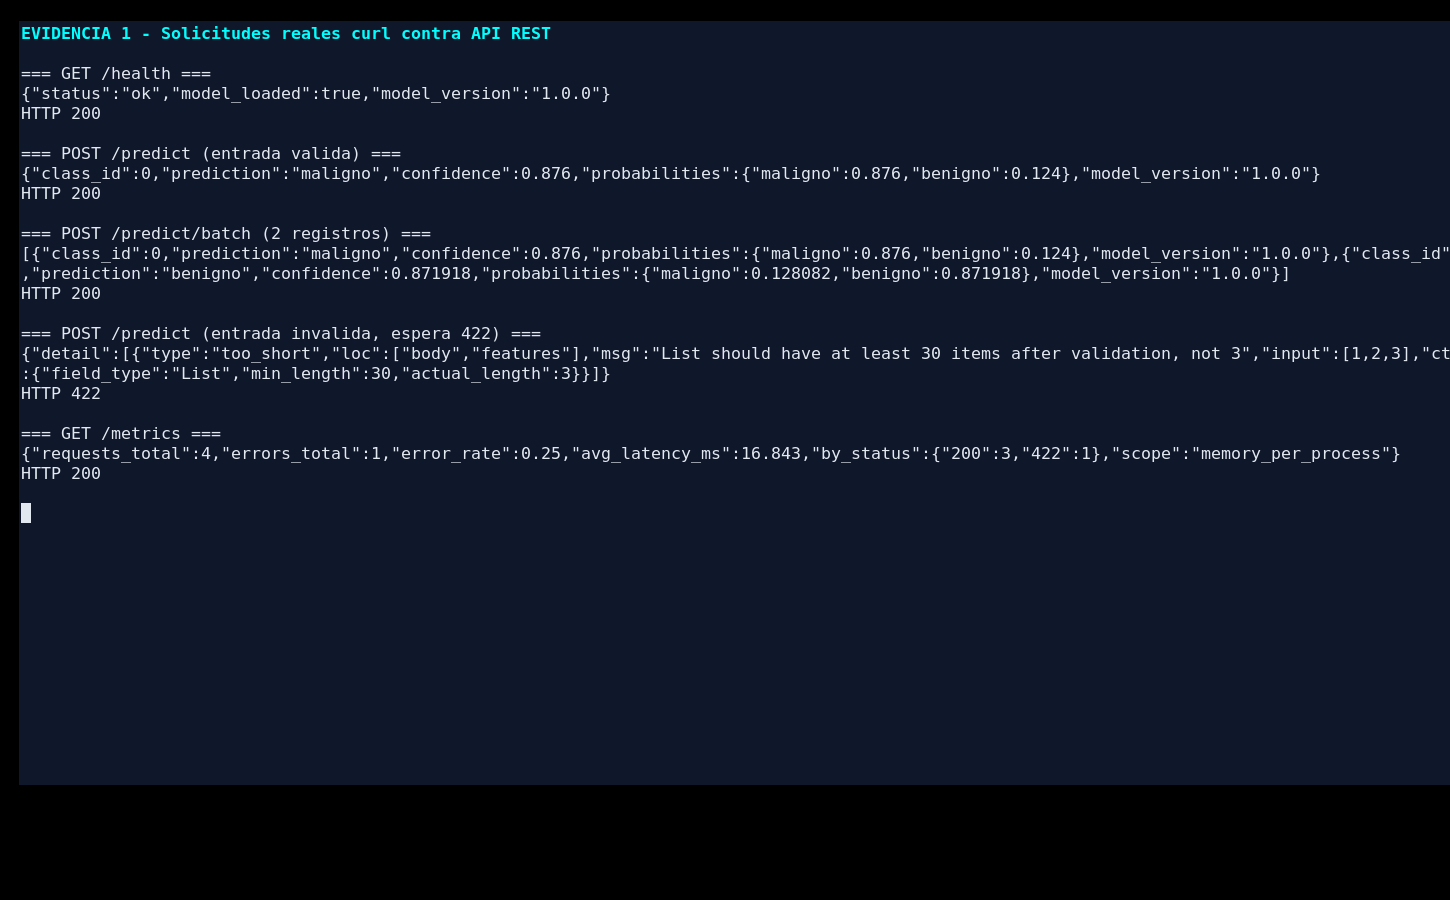

**Captura B. Nueve pruebas y logs**

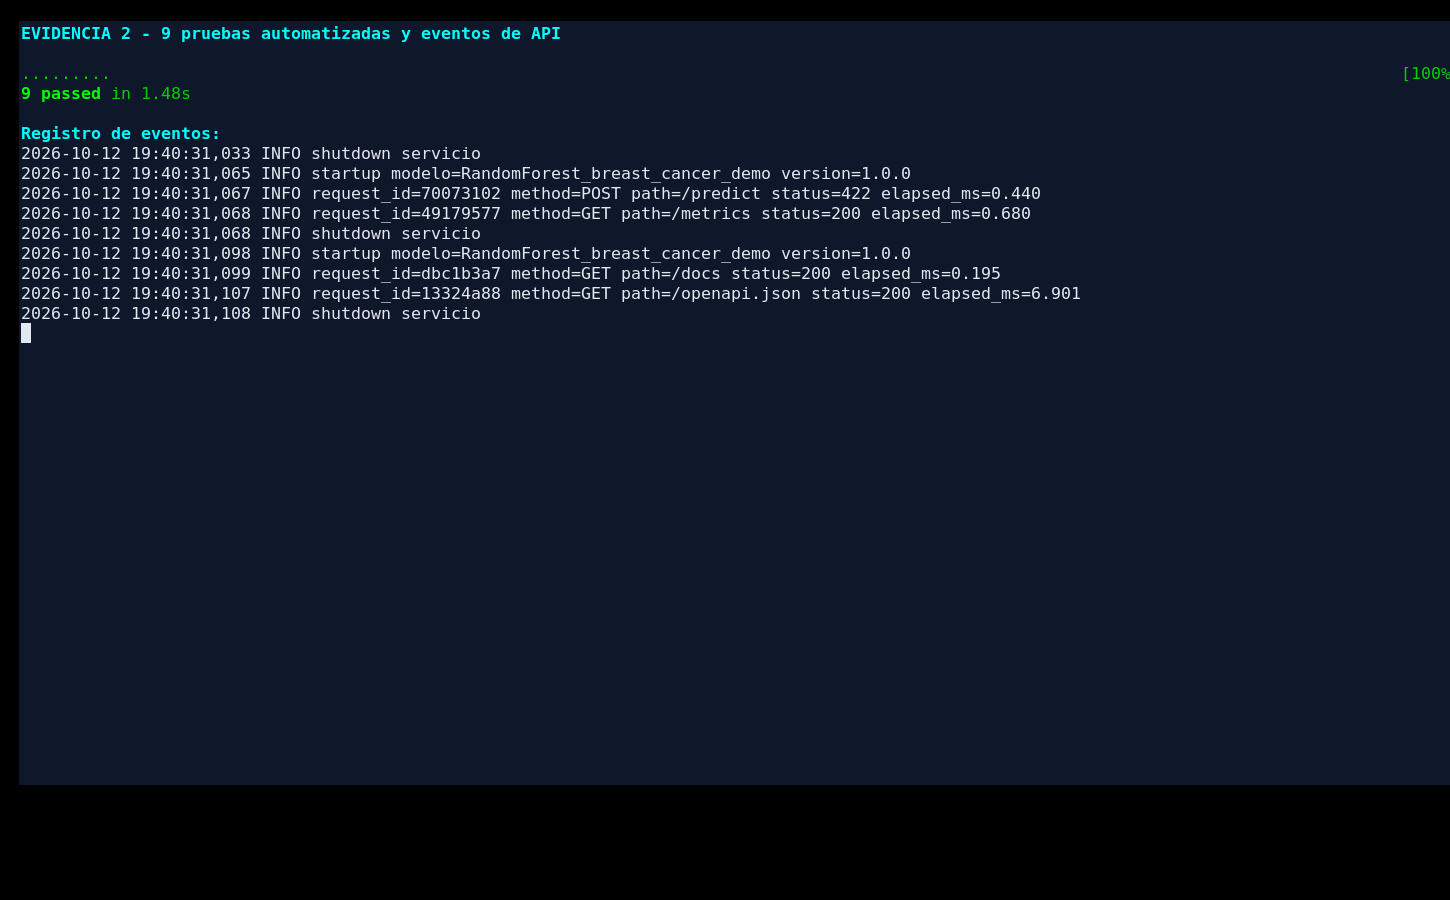

## 17. Reflexión y conclusiones

Implementar una API permite integrar un clasificador con otras aplicaciones que envían solicitudes JSON, sin tener que repetir el entrenamiento. Es tan importante verificar la exactitud del modelo como probar que el servicio responde correctamente, rechaza entradas inválidas y deja registros cuando ocurre un error.

En esta práctica, FastAPI proporcionó contratos de entrada y documentación OpenAPI; las pruebas de cURL y `pytest` confirmaron respuestas correctas (200) y rechazo de solicitudes erróneas (422); y las métricas de `/metrics` y los logs facilitaron el seguimiento básico. Para un servicio público real faltarían autenticación, HTTPS, control de recursos, despliegue persistente y observabilidad centralizada.

**Referencias:** [FastAPI](https://fastapi.tiangolo.com/), [pruebas FastAPI](https://fastapi.tiangolo.com/tutorial/testing/), [Uvicorn](https://www.uvicorn.org/), [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html).

**Para entregar:** descargar el notebook `.ipynb` y el ZIP del repositorio (incluye el mismo notebook, el código, tests, Postman, README y capturas).

### Cierre del servidor (opcional)

Cuando hayas terminado de capturar resultados, puedes detener el proceso para liberar el puerto.

In [ ]:
# Ejecuta solo si deseas detener la API al finalizar:
# api_process.terminate()
# api_process.wait(timeout=10)
# api_log_handle.close()